# Supporting Notebook 2

This notebook demonstrates that *16S rRNA* copy number does not impact estimations of niche breadth or optimum growth temperature for amplicon sequencing variants (ASVs)

In order to demonstrate that the number of *16S rRNA* copies a taxon has does not affect the distribution of its calculated absolute abundances (relative abundance from amplicon sequencing data multiplied by 16S qPCR on the same sample), we can plot the distribution of sequences using different hypothetical 16S copy numbers.

### Import libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Plot distribution of abundances for hypothetical ASVs with different marker gene copy numbers but the same number of reads

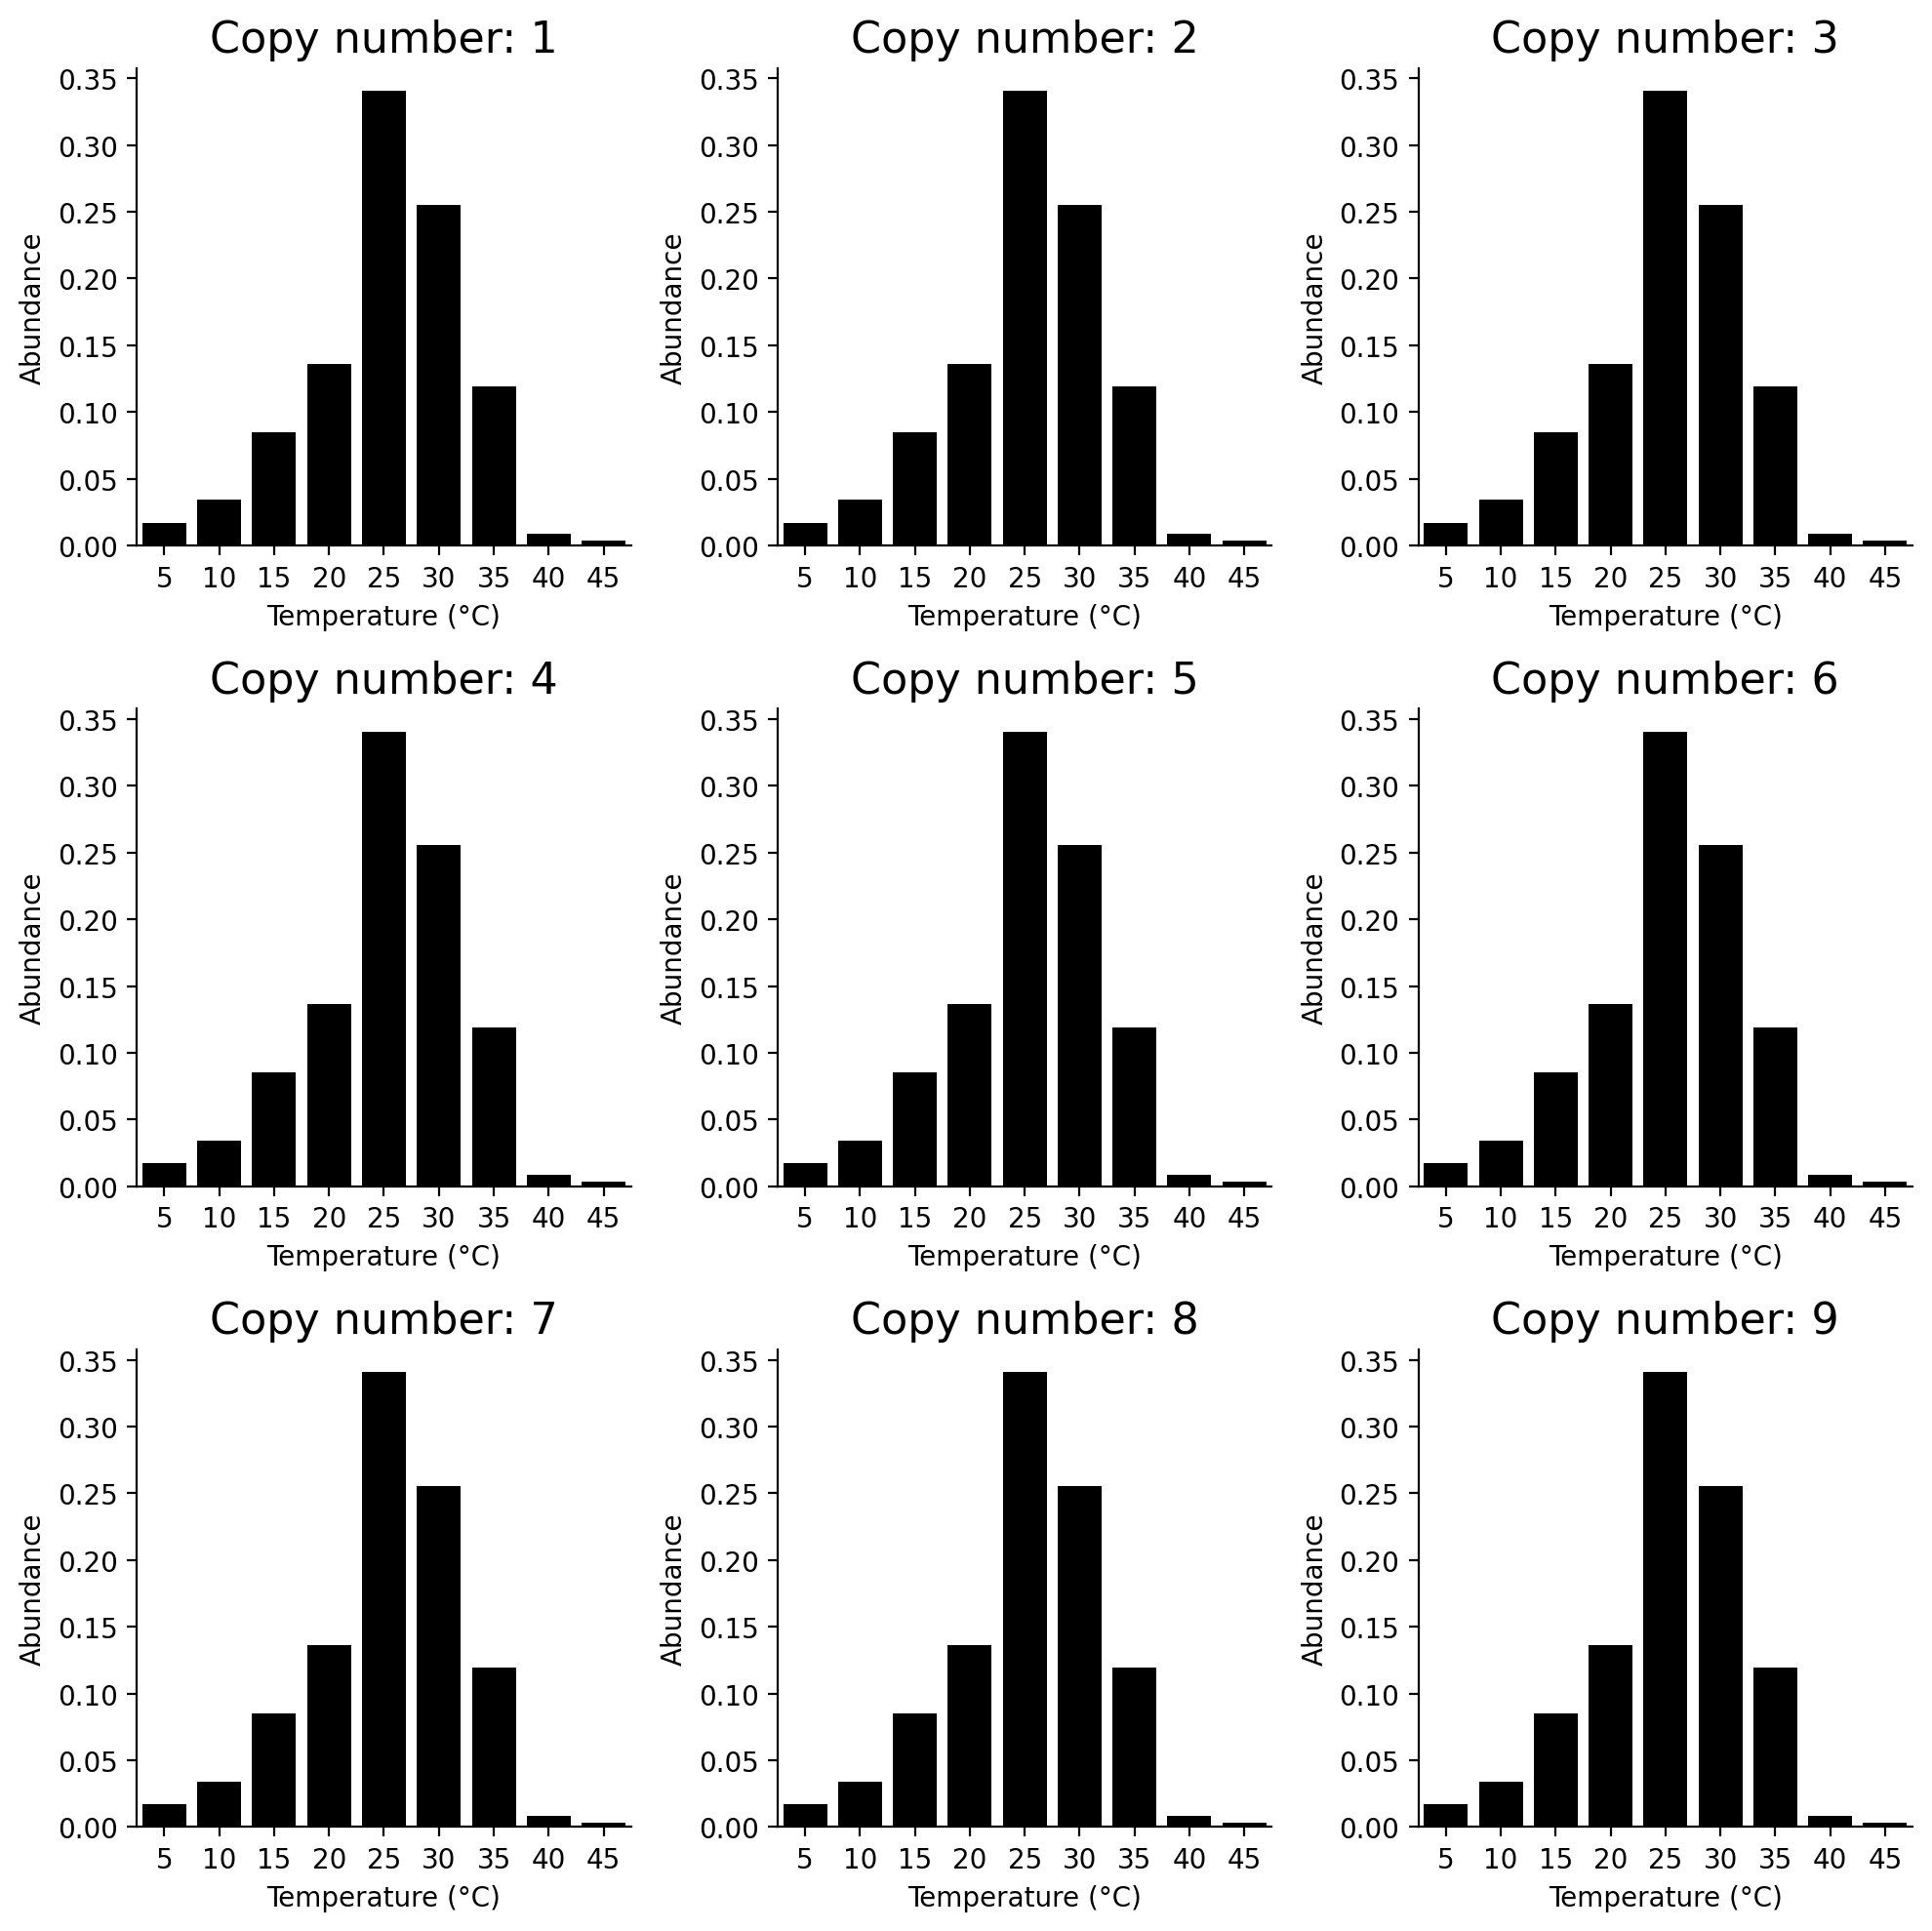

In [2]:
temps = [5,10,15,20,25,30,35,40,45]
reads = [100,200,500,800,2000,1500,700,50,20]

fig, axes = plt.subplots(ncols= 3, nrows= 3, dpi= 200, figsize= (10,10))
axes = axes.flatten()

for i in [1,2,3,4,5,6,7,8,9]:
    copy_number = i
    abundances = [value * copy_number for value in reads]
    abundances = [value/sum(abundances) for value in abundances]
    df = pd.DataFrame(zip(temps,abundances),
                      columns= ['Temperature (°C)','Abundance'])
    sns.barplot(df, x= 'Temperature (°C)', y= 'Abundance',
                color= 'k', ax= axes[i-1])
    axes[i-1].set_title(f"Copy number: {i}", fontsize= 16)

sns.despine()    
plt.tight_layout()

The distribution of an ASV's calculated absolute abundances remains identical, regardless of how many copies of the gene it has. As a result, estimation of niche breadth (using Levins' measure) or optimum growth temperature (by fitting thermal performance curves) is not biased by copy number variation in multi-copy marker genes so long as the method used to estimate abundance does not create such a bias (see Supporting_Notebook_1.ipynb).